# Model A, Taken Apart: a Hands-On Primer
**Series B: Deep Learning for Molecules, Post 6e** &nbsp;|&nbsp; companion *primer* notebook

Model A (Shee, Li, Zhang, ..., Newhouse and Batista, *Nature Communications* **15**, 7818, 2024) is a Transformer that reads a **product molecule** and *writes a reaction template*, together with a copy of the product in which the atoms that change are replaced by `*` (the **center-labeled product**). The template is then applied to the product with RDKit, which turns it into reactants. Models B and C (Posts 6f and 6g) are variants of the same idea.

> **Two parts.** **Part I** (everything up to the self-check) needs only NumPy, pandas and matplotlib and runs in about a minute. It rebuilds the model, and **if you have the authors' code folder** (`single_step_retro-main`, which includes the trained checkpoints) it also runs the authors' *real trained checkpoints* in NumPy, with no PyTorch and no RDKit, and reproduces outputs the authors saved in their notebooks. **Part II** (at the end) runs the authors' own PyTorch and RDKit code to turn templates into reactions and draw them; it needs PyTorch and RDKit (Colab has the first).
>
> **What this notebook is not.** It does not retrain the model, and without RDKit it cannot *apply* a template to a molecule: Part I works with template strings. Test accuracies are the authors'. Part II needs PyTorch and RDKit.

| Section | What you do |
|---|---|
| 1 | read a template and a center-labeled product; tokenize them |
| 2 | account for the network's parameters, and test a NumPy forward pass |
| 3 | decode with beam search; see what length normalization does |
| 4 | **(real weights)** read the checkpoint safely; recover the training length from the optimizer; reproduce the authors' outputs |
| 5 | **(real weights)** find the attention head that copies the product |
| 6 | from strings to reactions: the post-processing funnel and the Top-$K$ results |
| 7 | the data and the "cleaned" test set |
| **Part II** | run the authors' code and draw reactions |

## 0. Setup

In [ ]:
import itertools, math, re, io, os, sys, pickle, zipfile, collections, time, textwrap, subprocess
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = dict(blue="#0072B2", orange="#E69F00", green="#009E73", red="#D55E00", pink="#CC79A7", gray="#7f7f7f")

def _as_code_dir(p):
    """p may be the code folder or its 'code' subfolder: return the folder that contains model_library, or None."""
    p = Path(p)
    for q in (p, p / "code"):
        if q.is_dir() and (q / "model_library").is_dir(): return q.resolve()
    return None

def _search(root, max_depth=3, deadline=None, want="model_library"):
    """Walk `root` (at most `max_depth` levels down, skipping hidden folders, stopping at `deadline`) for a folder that contains `want` (case-insensitive)."""
    root = Path(root)
    if not root.is_dir(): return None
    base = len(root.parts)
    for dirpath, dirnames, _ in os.walk(root):
        if deadline and time.time() > deadline: return None
        hit = next((d for d in dirnames if d.lower() == want), None)
        if hit: return Path(dirpath).resolve()
        if len(Path(dirpath).parts) - base >= max_depth: dirnames[:] = []
        dirnames[:] = [d for d in dirnames if not d.startswith(".")]
    return None

def _find_zip(root, max_depth, deadline):
    root = Path(root); base = len(root.parts)
    for dirpath, dirnames, files in os.walk(root):
        if time.time() > deadline: return None
        for f in files:
            if f.lower().startswith("single_step_retro") and f.lower().endswith(".zip"): return Path(dirpath) / f
        if len(Path(dirpath).parts) - base >= max_depth: dirnames[:] = []
        dirnames[:] = [d for d in dirnames if not d.startswith(".")]
    return None

def _find_generic(mount_drive=True, max_depth=3, deep_seconds=90):
    """Find the authors' code folder 'single_step_retro-main': the folder that contains model_library.
    Order: environment variable CAPSULE_DIR; the working folder and /content; Google Drive (My Drive, 'Colab Notebooks');
    then a DEEP, time-limited search of Drive for the folder (or for single_step_retro*.zip, which is unzipped into /content/code_unzipped).
    In Colab it offers to mount Google Drive if the code folder is not found elsewhere."""
    hit = _as_code_dir(os.environ["CAPSULE_DIR"]) if os.environ.get("CAPSULE_DIR") else None
    if hit: return hit
    def roots():
        r = [Path.cwd()] + ([Path.cwd().parent] if len(Path.cwd().parent.parts) > 2 else []) + [Path("/content")]      # never walk "/" or a top-level system folder
        for drive in ("/content/drive/MyDrive", "/content/drive/My Drive", "/content/gdrive/MyDrive"):
            r += [Path(drive), Path(drive) / "Colab Notebooks"]
        return [x for x in dict.fromkeys(r) if x.is_dir()]
    def look():
        for r in roots():                                                         # the usual places first (cheap)
            for q in (r / "single_step_retro-main", r / "code", r):
                hit = _as_code_dir(q)
                if hit: return hit
        for r in roots():                                                         # a shallow search
            hit = _search(r, max_depth)
            if hit: return hit
        drives = [r for r in roots() if "drive" in str(r).lower() or "gdrive" in str(r).lower()]
        if drives:                                                                # a deep, time-limited search of Drive
            print(f"searching Google Drive more deeply (at most {deep_seconds} s) ...")
            deadline = time.time() + deep_seconds
            for r in drives[:1] + [d for d in drives[1:] if not str(d).startswith(str(drives[0]))]:
                hit = _search(r, 8, deadline)
                if hit: return hit
            for r in drives[:1]:
                z = _find_zip(r, 8, deadline)
                if z:
                    target = Path("/content/code_unzipped"); print("found", z, "-> unzipping into", target)
                    subprocess.run(["unzip", "-q", "-o", str(z), "-d", str(target)], check=False); hit = _search(target, 4)
                    if hit: return hit
        for r in roots():                                                         # a zip next to the notebook
            for z in sorted(r.glob("single_step_retro*.zip")):
                target = r / z.stem
                if not target.exists(): print("unzipping", z, "->", target); subprocess.run(["unzip", "-q", "-o", str(z), "-d", str(r)], check=False)
                hit = _search(r / z.stem, max_depth + 1) or _search(r, max_depth)
                if hit: return hit
        return None
    hit = look()
    if hit is None and mount_drive and not Path("/content/drive").exists():
        try:
            from google.colab import drive                                        # only exists in Colab; asks for your permission
            drive.mount("/content/drive"); hit = look()
        except Exception as e:
            print("(Google Drive was not mounted:", type(e).__name__, ")")
    if hit is None:                                                               # help the user see what Colab can see
        for r in roots():
            try: print(f"  {r}:", sorted(p.name for p in r.iterdir())[:20])
            except Exception as e: print(f"  {r}: cannot list ({type(e).__name__})")
    return hit


def find_capsule(**kw):
    # Stage 1: look for a folder named exactly 'single_step_retro-main' (the folder this notebook is written for), up to 8 levels deep in the working folder, /content and Google Drive. Stage 2: the generic search for any folder that contains model_library.
    env = os.environ.get("CAPSULE_DIR")
    if env and _as_code_dir(env): return _as_code_dir(env)
    if not Path("/content/drive").exists():
        try:
            from google.colab import drive; drive.mount("/content/drive")                       # only in Colab; asks for your permission
        except Exception: pass
    roots = [Path.cwd()] + ([Path.cwd().parent] if len(Path.cwd().parent.parts) > 2 else []) + [Path("/content")] + [Path(p) for p in ("/content/drive/MyDrive", "/content/drive/My Drive")]      # never walk "/" or a top-level system folder
    deadline = time.time() + 60
    for r in dict.fromkeys(x for x in roots if x.is_dir()):
        base = len(r.parts)
        for dirpath, dirnames, _ in os.walk(r):
            if time.time() > deadline: break
            if "single_step_retro-main" in dirnames and _as_code_dir(Path(dirpath) / "single_step_retro-main"): return _as_code_dir(Path(dirpath) / "single_step_retro-main")
            if len(Path(dirpath).parts) - base >= 8: dirnames[:] = []
            dirnames[:] = [d for d in dirnames if not d.startswith(".")]
    return _find_generic(**kw)

CAPSULE = find_capsule()
print("code folder found at:", CAPSULE if CAPSULE else "NOT FOUND: put the folder 'single_step_retro-main' (or its zip) next to this notebook, in /content, or in My Drive / Colab Notebooks, or set CAPSULE_DIR; to try your own prompt without the code, use https://models.batistalab.com/")

Mounted at /content/drive
code folder found at: /content/drive/MyDrive/Colab Notebooks/ML/temp/Blogs/single_step_retro-main


In [ ]:
# ---- reading the authors' pickles WITHOUT executing anything: list what a pickle would import, then read it with a whitelist-only reader
import pickletools
def pickle_globals(data):
    strs, found = [], set()
    for op, arg, pos in pickletools.genops(data):
        if op.name in ("SHORT_BINUNICODE", "BINUNICODE", "UNICODE"): strs.append(arg)
        if op.name == "GLOBAL": found.add(arg.replace(" ", "."))
        if op.name == "STACK_GLOBAL" and len(strs) >= 2: found.add(strs[-2] + "." + strs[-1])
    return sorted(found)

class _NoGlobals(pickle.Unpickler):
    def find_class(self, module, name): raise pickle.UnpicklingError(f"refused global {module}.{name}")
def load_plain_pickle(path):                                                           # for the small dictionary pickles (they import nothing)
    data = Path(path).read_bytes(); assert pickle_globals(data) == [], pickle_globals(data)
    return _NoGlobals(io.BytesIO(data)).load()

class _Storage:
    def __init__(self, key, numel): self.key, self.numel = key, numel
class _FloatStorage: pass
def _rebuild_tensor_v2(storage, offset, size, stride, requires_grad=False, backward_hooks=None, metadata=None): return ("tensor", storage, offset, tuple(size), tuple(stride))
class _CkptUnpickler(pickle.Unpickler):
    ALLOWED = {("collections", "OrderedDict"): collections.OrderedDict, ("torch", "FloatStorage"): _FloatStorage, ("torch._utils", "_rebuild_tensor_v2"): _rebuild_tensor_v2}
    def find_class(self, module, name):
        if (module, name) in self.ALLOWED: return self.ALLOWED[(module, name)]
        raise pickle.UnpicklingError(f"refused global {module}.{name}")
    def persistent_load(self, pid): return _Storage(str(pid[2]), int(pid[4]))

def load_checkpoint_numpy(path):
    """Read a PyTorch checkpoint (a zip with a pickle and raw tensor files) as NumPy arrays, importing only three standard tensor-storage names."""
    z = zipfile.ZipFile(path); pk = [n for n in z.namelist() if n.endswith("data.pkl")][0]; root = pk[:-len("data.pkl")]
    allowed = {"collections.OrderedDict", "torch.FloatStorage", "torch._utils._rebuild_tensor_v2"}
    unexpected = set(pickle_globals(z.read(pk))) - allowed
    assert not unexpected, f"the checkpoint imports something unexpected: {unexpected}"
    obj = _CkptUnpickler(io.BytesIO(z.read(pk))).load()
    def mat(o):
        if isinstance(o, tuple) and len(o) == 5 and o[0] == "tensor":
            _, st, off, size, stride = o; raw = np.frombuffer(z.read(root + "data/" + st.key), dtype="<f4")
            return np.lib.stride_tricks.as_strided(raw[off:], shape=size, strides=[s * 4 for s in stride]).copy() if len(size) else raw[off:off + 1].copy()
        if isinstance(o, dict): return type(o)((k, mat(v)) for k, v in o.items())
        if isinstance(o, (list, tuple)): return type(o)(mat(v) for v in o)
        return o
    return mat(obj)
print("safe readers defined")

safe readers defined


## 1. Templates, center-labeled products and tokens
A **reaction template** says which bonds change in a *retro*-direction: the left side matches the product, the right side gives what it is made from, and numbers after colons map atoms between the two sides. The authors use **site-specific templates** (radius 0): only the atoms that change and their immediate replacements, no neighbors, no special groups. Because such a template can match a product in several places, the model also writes the **center-labeled product**, in which the changed atoms are `*`: the template must apply *at those atoms*. The model's output is one string, `template_center-labeled product`.
**Stop and predict:** how many mapped product atoms does the template `[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]` have, and how many atoms are new on the reactant side?

In [ ]:
# ---- the tokenizer: characters, with two-letter atoms merged and '>>' merged; <SOS> first, '?' last (our re-implementation of the authors' 'character_consider_atoms')
TWO_LETTER_ATOMS = ["Ag","Al","As","Bi","Br","Ca","Cl","Cr","Cu","Ga","Ge","Hg","Li","Mg","Mn","Na","Pb","Pt","Ru","Sb","Se","Si","Sn","Ta","Te","Ti","Tl","Xe","Zn","Zr","se","si","te","Mo","Re"]
def tokenize(s):
    toks, has_added, skip = ["<SOS>"], False, False
    for i, c in enumerate(s):
        if skip: skip = False; continue
        if i < len(s) - 1 and c + s[i + 1] in TWO_LETTER_ATOMS: skip = True; toks.append(c + s[i + 1])
        elif c != ">": toks.append(c)
        elif not has_added: toks.append(">>"); has_added = True
    return toks + ["?"]

# ---- atoms in a SMILES string, in RDKit's numbering (the order of appearance), without RDKit
def smiles_atom_spans(smiles):
    spans, i, n = [], 0, len(smiles)
    while i < n:
        c = smiles[i]
        if c == "[":
            j = smiles.index("]", i); k = i + 1
            while k < j and smiles[k].isdigit(): k += 1                                   # isotope
            m = re.match(r"(Cl|Br|Si|Mg|Mn|Li|Cr|Cu|Zn|Al|Na|Ti|Ge|Zr|Bi|Sb|Te|As|Mo|Ga|Hg|Ta|Pb|Ru|Pt|Xe|Tl|Re|Ag|Ca|Sn|Se|se|si|te|[A-Za-z*])", smiles[k:j])
            spans.append((k, k + len(m.group(1)))); i = j + 1
        elif smiles[i:i + 2] in ("Cl", "Br"): spans.append((i, i + 2)); i += 2
        elif c in "BCNOPSFIbcnops*": spans.append((i, i + 1)); i += 1
        elif c == "%": i += 3
        else: i += 1                                                                   # bonds, branches, ring digits, '.', stereo marks
    return spans

def to_center_labeled(smiles, centers):
    """The center-labeled product: the element symbol of every atom whose index is in `centers` is replaced by '*'."""
    spans = smiles_atom_spans(smiles); out, last = [], 0
    for idx, (a, b) in enumerate(spans):
        out.append(smiles[last:a]); out.append("*" if idx in centers else smiles[a:b]); last = b
    out.append(smiles[last:]); return "".join(out)

def centers_of(center_labeled):
    return [i for i, (a, b) in enumerate(smiles_atom_spans(center_labeled)) if center_labeled[a:b] == "*"]

def star_positions(center_labeled):
    """Positions of the '*' tokens in the token sequence (position 0 is <SOS>): what Model B adds a '*' embedding at."""
    return [i for i, t in enumerate(tokenize(center_labeled)) if t == "*"]

def template_anatomy(template):
    """Split a retro template 'product side >> reactant side' into its parts."""
    left, right = template.split(">>"); maps = lambda s: re.findall(r":(\d+)\]", s)
    return dict(product_side=left, reactant_side=right, mapped_atoms=len(set(maps(left))), unmapped_new_atoms=len(re.findall(r"\[[^\]:]+\]|Br|Cl|[BCNOPSFI]", re.sub(r"\[[^\]]*:\d+\]", "", right))),
                reactant_fragments=len(right.split(".")), product_fragments=len(left.split(".")), intramolecular=len(left.split(".")) > 1)

# ---- tests against center-labeled products that the authors saved in their notebooks
assert to_center_labeled("C#CC1(C)CCCCC1=O", [0, 1]) == "*#*C1(C)CCCCC1=O"
_p = "CC(=O)OCC(=O)[C@@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C)C3=CC[C@]12C"
assert to_center_labeled(_p, [5, 6, 4, 3, 1, 2]) == "C*(=*)***(=*)[C@@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C)C3=CC[C@]12C"
_q, _clp = "CC(=O)c1ccc(Cn2ncc(NC(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1", "C*(=*)c1ccc(Cn2ncc(**(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1"
assert to_center_labeled(_q, centers_of(_clp)) == _clp and centers_of(_clp) == [1, 2, 12, 13]
assert star_positions("*#*C1(C)CCCCC1=O") == [1, 3]
print("the string-level atom tools reproduce the center-labeled products saved in the authors' notebooks")

the string-level atom tools reproduce the center-labeled products saved in the authors' notebooks


In [ ]:
# three templates the models actually generated (from the runs below and from the authors' notebooks)
examples = {"dibromoalkene -> alkyne": "[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]",
            "TMS-protected alkyne": "[CH:1]>>C-[Si](-C)(-C)-[C:1]",
            "amide from a ketal, an amine and an acid": "[C:4]-[NH:3].[C:2]=[O:1]>>C1-C-[O:1]-[C:2]-O-1.[NH2:3].O-[C:4]"}
print(pd.DataFrame({k: template_anatomy(v) for k, v in examples.items()}).T[["mapped_atoms", "unmapped_new_atoms", "reactant_fragments", "product_fragments", "intramolecular"]].to_string())
print("\nA template whose product side has several fragments ('.') is applied as INTRAMOLECULAR (the authors' code wraps the product side in parentheses, so all fragments must lie in one molecule).")

product = "C#CC1(C)CCCCC1=O"; clp = to_center_labeled(product, [0, 1])
out = "[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]_" + clp
print("\nproduct:", product, "| atoms:", len(smiles_atom_spans(product)), "| center-labeled with atoms 0 and 1:", clp)
print("model output string:", out); print("tokens of the product:", tokenize(product)); print("tokens of the output  :", tokenize(out)[:14], "...", len(tokenize(out)), "tokens")

                                         mapped_atoms unmapped_new_atoms reactant_fragments product_fragments intramolecular
dibromoalkene -> alkyne                             2                  2                  1                 1          False
TMS-protected alkyne                                1                  4                  1                 1          False
amide from a ketal, an amine and an acid            4                  4                  3                 2           True

A template whose product side has several fragments ('.') is applied as INTRAMOLECULAR (the authors' code wraps the product side in parentheses, so all fragments must lie in one molecule).

product: C#CC1(C)CCCCC1=O | atoms: 10 | center-labeled with atoms 0 and 1: *#*C1(C)CCCCC1=O
model output string: [C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]_*#*C1(C)CCCCC1=O
tokens of the product: ['<SOS>', 'C', '#', 'C', 'C', '1', '(', 'C', ')', 'C', 'C', 'C', 'C', 'C', '1', '=', 'O', '?']
tokens of the output  : ['

In [ ]:
# the vocabularies, if the code folder is here (A writes template + '_' + center-labeled product; B writes the template only)
if CAPSULE:
    smiledict_A, invdict_A = load_plain_pickle(CAPSULE / "data_AT/data_pickles/ModelA_dictionary.pickle")
    smiledict_B, invdict_B = load_plain_pickle(CAPSULE / "data_AT/data_pickles/ModelB_dictionary.pickle")
    print(f"Model A vocabulary: {len(smiledict_A)} tokens (+1 padding); Model B: {len(smiledict_B)} tokens (+1 padding)")
    print("tokens in A but not in B:", sorted(set(smiledict_A) - set(smiledict_B)), "| in B but not in A:", sorted(set(smiledict_B) - set(smiledict_A)))
    print("the end token is '?', the start token <SOS>, the mask token 'J' (training replaces 15 % of the product tokens by it); padding is the index", len(smiledict_A), "for A")
    assert len(smiledict_A) == 82 and len(smiledict_B) == 81 and smiledict_A["?"] == 24 and "_" in smiledict_A and "_" not in smiledict_B
else:
    print("no code folder: using the sizes 82 / 81 stated in the post")
    smiledict_A = smiledict_B = None

Model A vocabulary: 82 tokens (+1 padding); Model B: 81 tokens (+1 padding)
tokens in A but not in B: ['_'] | in B but not in A: []
the end token is '?', the start token <SOS>, the mask token 'J' (training replaces 15 % of the product tokens by it); padding is the index 82 for A


## 2. The network and its parameters
Models A and B are the same network: a **post-norm Transformer** (as in the Annotated-Transformer tutorials): token embeddings scaled by $\sqrt d$ plus **learned** position embeddings, 6 encoder and 6 decoder layers, $d=256$, 8 heads, feed-forward width $2d=512$ with ReLU, dropout 0.1. The encoder reads the product (padded to 310 tokens); the decoder writes the template string (up to 350 tokens) and attends to *all* encoder positions. (Model B additionally adds an embedding at the reaction-center positions; Model A does not use it.) The notebooks print 8,140,115 (A) and 8,139,346 (B) trainable parameters. Our formula should give exactly that.

In [ ]:
# ---- parameter counts of the Transformer (Model A / B shapes), from the architecture alone
def transformer_params(in_vocab, out_vocab, d=256, ff=512, layers=6, enc_len=310, dec_len=350):
    ln, mha = 2 * d, 4 * (d * d + d); fnn = d * ff + ff + ff * d + d
    enc = in_vocab * d + enc_len * d + layers * (2 * ln + mha + fnn)
    dec = out_vocab * d + dec_len * d + layers * (3 * ln + 2 * mha + fnn) + d * out_vocab + out_vocab
    return enc, dec

In [ ]:
rows = []
for name, vocab, printed in (("Model A", 83, 8_140_115), ("Model B", 82, 8_139_346)):
    enc, dec = transformer_params(vocab, vocab); rows.append((name, vocab, f"{enc:,}", f"{dec:,}", f"{enc + dec:,}", f"{printed:,}"))
    assert enc + dec == printed
print(pd.DataFrame(rows, columns=["model", "vocabulary (+pad)", "encoder", "decoder", "total (our formula)", "printed in the authors' notebook"]).to_string(index=False))
d, ff = 256, 512; ln, mha, fnn = 2 * d, 4 * (d * d + d), d * ff + ff + ff * d + d
print(f"\none encoder layer: attention {mha:,} + feed-forward {fnn:,} + 2 layer norms {2 * ln:,} = {mha + fnn + 2 * ln:,}; one decoder layer: 2 attention {2 * mha:,} + feed-forward + 3 norms = {2 * mha + fnn + 3 * ln:,}")
enc, dec = transformer_params(83, 83); emb = 83 * d * 2 + (310 + 350) * d
print(f"the decoder holds {100 * dec / (enc + dec):.1f} % (it has two attention blocks per layer); the embedding tables hold {emb:,} = {100 * emb / (enc + dec):.1f} %: the vocabulary is tiny, the learned position tables are {100 * (310 + 350) * d / emb:.0f} % of that")

  model  vocabulary (+pad)   encoder   decoder total (our formula) printed in the authors' notebook
Model A                 83 3,263,232 4,876,883           8,140,115                        8,140,115
Model B                 82 3,262,976 4,876,370           8,139,346                        8,139,346

one encoder layer: attention 263,168 + feed-forward 262,912 + 2 layer norms 1,024 = 527,104; one decoder layer: 2 attention 526,336 + feed-forward + 3 norms = 790,784
the decoder holds 59.9 % (it has two attention blocks per layer); the embedding tables hold 211,456 = 2.6 %: the vocabulary is tiny, the learned position tables are 80 % of that


In [ ]:
# ---- the authors' Model A / Model B network in NumPy: post-norm Transformer, learned position embeddings, ReLU feed-forward, 6+6 layers
def softmax(x, ax=-1):
    e = np.exp(x - x.max(ax, keepdims=True)); return e / e.sum(ax, keepdims=True)
def layer_norm(x, w, b, eps=1e-5):
    m = x.mean(-1, keepdims=True); v = x.var(-1, keepdims=True); return (x - m) / np.sqrt(v + eps) * w + b
def linear(x, W, b): return x @ W.T + b                                               # PyTorch stores nn.Linear weights as (out, in)

class TemplateTransformerNP:
    def __init__(self, sd, n_heads=8, n_layers=6):
        self.sd, self.h, self.L = sd, n_heads, n_layers; self.d = sd["decoder.tok_embedding.weight"].shape[1]
    def attention(self, p, q_in, kv_in, keep):                                         # keep: True where attention is allowed
        sd, d, h = self.sd, self.d, self.h; dh = d // h; B, Lq, _ = q_in.shape; Lk = kv_in.shape[1]
        Q = linear(q_in, sd[p + ".fc_q.weight"], sd[p + ".fc_q.bias"]).reshape(B, Lq, h, dh).transpose(0, 2, 1, 3)
        K = linear(kv_in, sd[p + ".fc_k.weight"], sd[p + ".fc_k.bias"]).reshape(B, Lk, h, dh).transpose(0, 2, 1, 3)
        V = linear(kv_in, sd[p + ".fc_v.weight"], sd[p + ".fc_v.bias"]).reshape(B, Lk, h, dh).transpose(0, 2, 1, 3)
        e = np.where(keep, Q @ K.transpose(0, 1, 3, 2) / math.sqrt(dh), -1e10); a = softmax(e)
        return linear((a @ V).transpose(0, 2, 1, 3).reshape(B, Lq, d), sd[p + ".fc_o.weight"], sd[p + ".fc_o.bias"]), a
    def feed_forward(self, p, x):
        sd = self.sd; return linear(np.maximum(linear(x, sd[p + ".fc_1.weight"], sd[p + ".fc_1.bias"]), 0), sd[p + ".fc_2.weight"], sd[p + ".fc_2.bias"])
    def encode(self, product, pad_idx, star_positions=None, star_token=None):
        """product: (B, Ls) token ids. star_positions (Model B): list of positions per example; a '*' embedding is ADDED there."""
        sd, d = self.sd, self.d; pre = "conditioner.encoder."; B, Ls = product.shape; keep = (product != pad_idx)[:, None, None, :]
        x = sd[pre + "tok_embedding.weight"][product]
        if star_positions is not None:
            onehot = np.zeros((B, Ls), dtype=np.int64)
            for b in range(B):
                for pos in star_positions[b]:
                    if pos > 0: onehot[b, pos] = star_token                            # position 0 is reserved, as in the authors' code
            x = x + sd[pre + "tok_embedding.weight"][onehot] * (onehot != 0)[..., None]
        x = x * math.sqrt(d) + sd[pre + "pos_embedding.weight"][np.arange(Ls)][None]
        for l in range(self.L):
            p = f"{pre}layers.{l}"; a, _ = self.attention(p + ".self_attention", x, x, keep)
            x = layer_norm(x + a, sd[p + ".self_attn_layer_norm.weight"], sd[p + ".self_attn_layer_norm.bias"])
            x = layer_norm(x + self.feed_forward(p + ".positionwise_feedforward", x), sd[p + ".ff_layer_norm.weight"], sd[p + ".ff_layer_norm.bias"])
        return x, keep
    def decode(self, trg, memory, memory_keep, pad_idx):
        sd, d = self.sd, self.d; B, t = trg.shape
        x = sd["decoder.tok_embedding.weight"][trg] * math.sqrt(d) + sd["decoder.pos_embedding.weight"][np.arange(t)][None]
        keep = (trg != pad_idx)[:, None, None, :] & np.tril(np.ones((t, t), dtype=bool))[None, None]; att = None
        for l in range(self.L):
            p = f"decoder.layers.{l}"; a, _ = self.attention(p + ".self_attention", x, x, keep)
            x = layer_norm(x + a, sd[p + ".self_attn_layer_norm.weight"], sd[p + ".self_attn_layer_norm.bias"])
            a, att = self.attention(p + ".encoder_attention", x, memory, memory_keep)
            x = layer_norm(x + a, sd[p + ".enc_attn_layer_norm.weight"], sd[p + ".enc_attn_layer_norm.bias"])
            x = layer_norm(x + self.feed_forward(p + ".positionwise_feedforward", x), sd[p + ".ff_layer_norm.weight"], sd[p + ".ff_layer_norm.bias"])
        return linear(x, sd["decoder.fc_out.weight"], sd["decoder.fc_out.bias"]), att        # logits and the LAST layer's cross-attention (B, heads, t, Ls)

def beam_search(model, smiledict, invdict, product_tokens, beam_size=10, star_positions=None, max_len=349, product_len=310):
    """The authors' beam search, re-implemented: candidates are ranked by log-probability / sqrt(number of non-pad tokens); finished beams (token '?') are carried along."""
    pad, end = len(smiledict), smiledict["?"]
    prod = np.array([[smiledict[t] for t in product_tokens] + [pad] * (product_len - len(product_tokens))])
    mem, keep = model.encode(prod, pad, None if star_positions is None else [star_positions], smiledict.get("*"))
    logits, _ = model.decode(np.zeros((1, 1), dtype=np.int64), mem, keep, pad)
    lp = np.log(softmax(logits[0, -1])); top = np.minimum(np.argsort(lp)[::-1][:beam_size], pad)
    seqs = [[0, int(t)] for t in top]; probs = np.array([lp[t] for t in top])
    for step in range(max_len - 2):
        if all(end in s for s in seqs): break                                           # (the authors' code keeps looping with padding; the result is the same)
        L = max(len(s) for s in seqs); trg = np.array([s + [pad] * (L - len(s)) for s in seqs])
        logits, _ = model.decode(trg, np.repeat(mem, len(seqs), 0), np.repeat(keep, len(seqs), 0), pad); cs, cp = [], []
        for k, s in enumerate(seqs):
            if end not in s:
                vec = probs[k] + np.log(softmax(logits[k, len(s) - 1])); tk = np.minimum(np.argsort(vec)[::-1][:beam_size], pad)
                for j in tk: cs.append(s + [int(j)]); cp.append(vec[j])
            else: cs.append(s + [pad]); cp.append(probs[k])
        norm = [p / math.sqrt(sum(1 for t in s if t != pad)) for s, p in zip(cs, cp)]
        best = np.argsort(norm)[::-1][:beam_size]; seqs = [cs[i] for i in best]; probs = np.array([cp[i] for i in best])
    out = []
    for s, p in zip(seqs, probs):
        text = ""
        for t in s:
            if invdict[t] == "?": break
            text += invdict[t]
        out.append((text[5:], float(p)))                                                # drop the leading '<SOS>'
    return out
print("NumPy network and beam search defined")

NumPy network and beam search defined


In [ ]:
# a random-weight network with the authors' parameter names, to test the NumPy forward pass without any checkpoint
def random_state_dict(in_vocab, out_vocab, d=256, ff=512, layers=6, enc_len=310, dec_len=350, seed=0):
    r = np.random.default_rng(seed); sd = {}; W = lambda *s: (r.normal(size=s) * 0.05).astype(np.float32)
    def attn(p):
        for n in ("q", "k", "v", "o"): sd[f"{p}.fc_{n}.weight"], sd[f"{p}.fc_{n}.bias"] = W(d, d), W(d)
    def ffn(p): sd[p + ".fc_1.weight"], sd[p + ".fc_1.bias"], sd[p + ".fc_2.weight"], sd[p + ".fc_2.bias"] = W(ff, d), W(ff), W(d, ff), W(d)
    def norm(p): sd[p + ".weight"], sd[p + ".bias"] = np.ones(d, np.float32), np.zeros(d, np.float32)
    sd["decoder.tok_embedding.weight"], sd["decoder.pos_embedding.weight"] = W(out_vocab, d), W(dec_len, d)
    for l in range(layers):
        p = f"decoder.layers.{l}"; attn(p + ".self_attention"); attn(p + ".encoder_attention"); ffn(p + ".positionwise_feedforward")
        for n in ("self_attn_layer_norm", "enc_attn_layer_norm", "ff_layer_norm"): norm(f"{p}.{n}")
    sd["decoder.fc_out.weight"], sd["decoder.fc_out.bias"] = W(out_vocab, d), W(out_vocab)
    pre = "conditioner.encoder."; sd[pre + "tok_embedding.weight"], sd[pre + "pos_embedding.weight"] = W(in_vocab, d), W(enc_len, d)
    for l in range(layers):
        p = f"{pre}layers.{l}"; attn(p + ".self_attention"); ffn(p + ".positionwise_feedforward"); norm(p + ".self_attn_layer_norm"); norm(p + ".ff_layer_norm")
    return sd

sd_rand = random_state_dict(83, 83); n_rand = sum(v.size for v in sd_rand.values())
print(f"random network: {n_rand:,} parameters; formula {sum(transformer_params(83, 83)):,}"); assert n_rand == sum(transformer_params(83, 83))
NP = TemplateTransformerNP(sd_rand); pad = 82; rg = np.random.default_rng(1)
toks = rg.integers(0, 82, 30); P = np.array([list(toks) + [pad] * 280]); mem, keep = NP.encode(P, pad)
trg = rg.integers(0, 82, (1, 20)); lg, att = NP.decode(trg, mem, keep, pad); print("logits", lg.shape, "| last-layer cross-attention", att.shape, "(batch, heads, output positions, product positions)")
trg2 = trg.copy(); trg2[0, 10:] = rg.integers(0, 82, 10); lg2, _ = NP.decode(trg2, mem, keep, pad)
print(f"change the output tokens from position 10 on: change of the logits at positions 0-9 = {np.abs(lg[0, :10] - lg2[0, :10]).max():.1e} (causal mask), at 10-19 = {np.abs(lg[0, 10:] - lg2[0, 10:]).max():.2f}")
P2 = np.array([list(toks) + [pad] * 270]); mem2, keep2 = NP.encode(P2, pad)
print(f"pad the product to 300 instead of 310 tokens: change of the output logits = {np.abs(NP.decode(trg, mem2, keep2, pad)[0] - lg).max():.1e} (padding is masked out); a product LONGER than 310 tokens cannot be encoded at all: the learned position table has 310 rows")
assert np.abs(lg[0, :10] - lg2[0, :10]).max() == 0 and np.abs(NP.decode(trg, mem2, keep2, pad)[0] - lg).max() < 1e-4
# Model B's reaction-center embedding: an embedding of the '*' token ADDED at the chosen positions
star_tok = 19; memS, _ = NP.encode(P, pad, star_positions=[[3, 7]], star_token=star_tok); memN, _ = NP.encode(P, pad)
print(f"adding the '*' embedding at two positions changes the encoder output by {np.abs(memS - memN).max():.2f}; with no star positions: {np.abs(NP.encode(P, pad, star_positions=[[]], star_token=star_tok)[0] - memN).max():.1e}")

random network: 8,140,115 parameters; formula 8,140,115
logits (1, 20, 83) | last-layer cross-attention (1, 8, 20, 310) (batch, heads, output positions, product positions)
change the output tokens from position 10 on: change of the logits at positions 0-9 = 0.0e+00 (causal mask), at 10-19 = 0.77
pad the product to 300 instead of 310 tokens: change of the output logits = 0.0e+00 (padding is masked out); a product LONGER than 310 tokens cannot be encoded at all: the learned position table has 310 rows
adding the '*' embedding at two positions changes the encoder output by 1.22; with no star positions: 0.0e+00


## 3. Decoding: beam search with a length penalty
The model gives a probability for the next token; a candidate string is a path through those choices. **Beam search** keeps the `beam_size` best partial strings. The authors' code ranks candidates by $\log p/\sqrt{\ell}$ (the log-probability divided by the square root of the number of tokens so far), a compromise between the raw log-probability (which favors short strings) and the per-token average ($\ell^{1}$). We see the effect exactly on a tiny language with a fixed end probability.

In [ ]:
rng4 = np.random.default_rng(1); nt, p_end = 3, 0.25
P4 = np.zeros((nt + 1, nt + 1))
for r in range(nt + 1): P4[r, :nt] = rng4.dirichlet(np.ones(nt) * 1.2) * (1 - p_end); P4[r, nt] = p_end
def logp(seq):
    prev, lp = nt, 0.0
    for t in seq: lp += np.log(P4[prev, t]); prev = t
    return lp + np.log(P4[prev, nt])
allseq = [s for L in range(0, 9) for s in itertools.product(range(nt), repeat=L)]
raw = np.array([logp(s) for s in allseq]); ln_ = np.array([len(s) + 1 for s in allseq])
rows = []
for alpha, label in ((0.0, "raw log-probability (exponent 0)"), (0.5, "divided by sqrt(length): the authors' choice"), (1.0, "per-token average (exponent 1)")):
    top = np.argsort(-(raw / ln_ ** alpha))[:5]; rows.append((label, [len(allseq[i]) for i in top], np.mean([len(allseq[i]) for i in top])))
print(pd.DataFrame(rows, columns=["ranking score", "lengths of the best 5", "mean length"]).to_string(index=False))
print("\nin this toy the sqrt exponent only nudges the best lengths (mean 1.0 -> 1.2) while the per-token average flips them to the longest strings (7.4): the authors' exponent is a mild correction, not a full normalization (here the end token has a fixed probability; a trained model emits it when the template is complete)")

                               ranking score lengths of the best 5  mean length
            raw log-probability (exponent 0)       [0, 1, 1, 1, 2]          1.0
divided by sqrt(length): the authors' choice       [0, 1, 1, 2, 2]          1.2
              per-token average (exponent 1)       [8, 7, 8, 6, 8]          7.4

in this toy the sqrt exponent only nudges the best lengths (mean 1.0 -> 1.2) while the per-token average flips them to the longest strings (7.4): the authors' exponent is a mild correction, not a full normalization (here the end token has a fixed probability; a trained model emits it when the template is complete)


## 4. The real checkpoints, read safely and run in NumPy
*(This section needs the code folder `single_step_retro-main`, which includes the trained checkpoints; otherwise it is skipped.)* A PyTorch checkpoint is a zip file holding a **pickle** plus raw tensors. A pickle can execute code, so we do **not** load it with `torch.load` here: we list what the pickle would import, check that it is only the three standard tensor-storage names, and read it with a reader that allows exactly those. The result is NumPy arrays that we feed to the network above.

In [ ]:
if CAPSULE:
    CK = {"A": CAPSULE / "model_checkpoints/ModelA_AT_DATA_256DIM_0Radius_6Layer_Seq2Seq_112_Batch_5e5_LR_810EP_MASK_ATOM.cpth",
          "B": CAPSULE / "model_checkpoints/ModelB_AT_DATA_256DIM_0Radius_6Layer_Seq2Seq_112_Batch_4e5_LR_570EP_MASK_ATOM.cpth"}
    z = zipfile.ZipFile(CK["A"]); pk = [n for n in z.namelist() if n.endswith("data.pkl")][0]
    print("what the checkpoint's pickle would import:", pickle_globals(z.read(pk)))
    ckpt, sd_real = {}, {}
    for m in "AB": ckpt[m] = load_checkpoint_numpy(CK[m]); sd_real[m] = ckpt[m]["model_state_dict"]
    rows = []
    for m, printed in (("A", 8_140_115), ("B", 8_139_346)):
        n = sum(v.size for v in sd_real[m].values()); steps = int(np.asarray(next(iter(ckpt[m]["optimizer_state_dict"]["state"].values()))["step"]).reshape(-1)[0])
        epochs = {"A": 810, "B": 570}[m]; opt = ckpt[m]["optimizer_state_dict"]["param_groups"][0]
        rows.append((f"Model {m}", len(sd_real[m]), f"{n:,}", f"{printed:,}", f"{steps:,}", f"{steps / epochs:,.0f}", opt["lr"]))
        assert n == printed
    print(pd.DataFrame(rows, columns=["", "tensors", "parameters", "printed by the authors", "Adam steps taken", "steps / epochs in the file name", "learning rate stored"]).to_string(index=False))
    print("\nBoth checkpoints have exactly the number of parameters the authors print, and the SAME 6,786 steps per epoch. With the batch of 112 in the file name,")
    print(f"6,786 steps x 112 = {6786 * 112:,} reactions per epoch: the filtered training set has about 760,000 reactions ({100 * 760_032 / 768_808:.1f} % of the 768,808 in the file); both runs saw it 810 and 570 times (derived from the optimizer's step counter).")
    assert round(5_496_660 / 810) == 6786 and round(3_868_020 / 570) == 6786

what the checkpoint's pickle would import: ['collections.OrderedDict', 'torch.FloatStorage', 'torch._utils._rebuild_tensor_v2']
         tensors parameters printed by the authors Adam steps taken steps / epochs in the file name  learning rate stored
Model A      258  8,140,115              8,140,115        5,496,660                           6,786               0.00005
Model B      258  8,139,346              8,139,346        3,868,020                           6,786               0.00004

Both checkpoints have exactly the number of parameters the authors print, and the SAME 6,786 steps per epoch. With the batch of 112 in the file name,
6,786 steps x 112 = 760,032 reactions per epoch: the filtered training set has about 760,000 reactions (98.9 % of the 768,808 in the file); both runs saw it 810 and 570 times (derived from the optimizer's step counter).


In [ ]:
# which rows of the learned position tables moved away from their random initialisation?  nn.Embedding starts at N(0,1): a 256-vector has norm 16 +- 0.7
if CAPSULE:
    rows = []
    for m in "AB":
        for tag, key, L in (("encoder (product, 310 slots)", "conditioner.encoder.pos_embedding.weight", 310), ("decoder (template, 350 slots)", "decoder.pos_embedding.weight", 350)):
            nrm = np.linalg.norm(sd_real[m][key], axis=1); moved = np.abs(nrm - 16) > 2.2
            rows.append((f"Model {m}", tag, f"{nrm[:5].mean():.1f}", f"{nrm[-20:].mean():.1f}", f"{100 * moved.mean():.0f} %", int(np.max(np.where(moved)[0]))))
    print(pd.DataFrame(rows, columns=["", "position table", "mean norm, first 5 slots", "mean norm, last 20 slots", "slots clearly moved from init", "last moved slot"]).to_string(index=False))
    print("the early slots grew to norms of 25-40; the last slots still look like their random start: the training strings are mostly much shorter than the allowed 310 and 350 tokens (our reading of the norms)")

                       position table mean norm, first 5 slots mean norm, last 20 slots slots clearly moved from init  last moved slot
Model A  encoder (product, 310 slots)                     34.1                     16.1                          44 %              241
Model A decoder (template, 350 slots)                     24.6                     16.4                          40 %              322
Model B  encoder (product, 310 slots)                     33.6                     16.0                          26 %              242
Model B decoder (template, 350 slots)                     23.1                     16.2                          20 %              309
the early slots grew to norms of 25-40; the last slots still look like their random start: the training strings are mostly much shorter than the allowed 310 and 350 tokens (our reading of the norms)


In [ ]:
# run the REAL Model A on the product of the authors' attention notebook, with beam size 1, and compare with what they saved
if CAPSULE:
    MA = TemplateTransformerNP(sd_real["A"]); product_att = "CC(=O)c1ccc(Cn2ncc(NC(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1"
    t0 = time.time(); res = beam_search(MA, smiledict_A, invdict_A, tokenize(product_att), beam_size=1); print(f"greedy decoding in NumPy: {time.time() - t0:.1f} s")
    template, clp_gen = res[0][0].split("_"); print("generated template:", template); print("generated center-labeled product:", clp_gen)
    saved = "C*(=*)c1ccc(Cn2ncc(**(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1"
    print("the authors' notebook saved the center-labeled product:", saved, "\nidentical:", clp_gen == saved); assert clp_gen == saved
    print("\ntemplate anatomy:", {k: v for k, v in template_anatomy(template).items() if k in ("mapped_atoms", "reactant_fragments", "product_fragments", "intramolecular")}, "\ncenters (atom indices of the product):", centers_of(clp_gen))
    print("(read it as: the two ketal oxygens from ethylene glycol appear on the ketone carbon; an NH2 and a carboxylic acid O-[C:4] are the amine and acid of the amide: the same reactants the authors printed)")

greedy decoding in NumPy: 6.9 s
generated template: [C:4]-[NH:3].[C:2]=[O:1]>>C1-C-[O:1]-[C:2]-O-1.[NH2:3].O-[C:4]
generated center-labeled product: C*(=*)c1ccc(Cn2ncc(**(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1
the authors' notebook saved the center-labeled product: C*(=*)c1ccc(Cn2ncc(**(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1 
identical: True

template anatomy: {'mapped_atoms': 4, 'reactant_fragments': 3, 'product_fragments': 2, 'intramolecular': True} 
centers (atom indices of the product): [1, 2, 12, 13]
(read it as: the two ketal oxygens from ethylene glycol appear on the ketone carbon; an NH2 and a carboxylic acid O-[C:4] are the amine and acid of the amide: the same reactants the authors printed)


In [ ]:
# the cyclohexanone derivative of the tutorial: beam size 10; candidates are then sorted by raw log-probability (as the authors' code does after filtering)
if CAPSULE:
    t0 = time.time(); resA10 = beam_search(MA, smiledict_A, invdict_A, tokenize("C#CC1(C)CCCCC1=O"), beam_size=10); print(f"beam 10 in NumPy: {time.time() - t0:.1f} s (the authors' log shows 16 s on a GPU for 347 steps without early stopping)")
    rows = []
    for rank, (s, p) in enumerate(sorted(resA10, key=lambda x: -x[1]), 1):
        t, c = s.split("_"); rows.append((rank, f"{p:.2f}", t, c, centers_of(c)))
    print(pd.DataFrame(rows, columns=["rank", "log p", "template", "center-labeled product", "centers"]).to_string(index=False))
    top_tmpl = sorted(resA10, key=lambda x: -x[1])[0][0].split("_")[0]
    print("\nthe authors' notebook printed the top reaction 'CC1(C#C[Si](C)(C)C)CCCCC1=O>>C#CC1(C)CCCCC1=O': a TMS-protected alkyne, i.e. the template", top_tmpl)
    assert top_tmpl == "[CH:1]>>C-[Si](-C)(-C)-[C:1]"
    print("the dibromoalkene template of Model B's top result appears in A's beam too:", any(s.split("_")[0] == "[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]" for s, _ in resA10))

beam 10 in NumPy: 52.2 s (the authors' log shows 16 s on a GPU for 347 steps without early stopping)
 rank log p                                                       template center-labeled product centers
    1 -1.40                                   [CH:1]>>C-[Si](-C)(-C)-[C:1]       *#CC1(C)CCCCC1=O     [0]
    2 -2.53                                [C:2]-[CH3:1]>>I-[CH3:1].[CH:2]       C#C*1(*)CCCCC1=O  [2, 3]
    3 -3.11                     [C:2]#[CH:1]>>O=[C:1](-[O-])-[O-].O=[CH:2]       *#*C1(C)CCCCC1=O  [0, 1]
    4 -3.14                                     [C:1]=[O:2]>>[CH:1]-[OH:2]       C#CC1(C)CCCC*1=*  [8, 9]
    5 -3.25                             [C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]       *#*C1(C)CCCCC1=O  [0, 1]
    6 -3.35 [C:2]-[CH3:1]>>C-[Si](-C)(-C)-[N-]-[Si](-C)(-C)-[CH3:1].[CH:2]       C#C*1(*)CCCCC1=O  [2, 3]
    7 -3.94               [C:2]-[CH3:1]>>C-C(-C)-[N-]-C(-C)-[CH3:1].[CH:2]       C#C*1(*)CCCCC1=O  [2, 3]
    8 -4.16                [C:2]-[CH3:1]>>C-C(-C)-[

## 5. An attention head that copies the product
The decoder writes the center-labeled product *token by token*, and that string is the product with a few atoms replaced by `*`: mostly a **copy**. The cross-attention of the last decoder layer (8 heads) tells us where each output token looks in the product. We test, on real weights, whether some head attends to the *aligned* product token: output token $m$ of the center-labeled product is the copy of product token $m$ (plus the start token). The authors' attention notebook plots head 6 by default.
**Stop and predict:** how many of the 8 heads copy?

In [ ]:
if CAPSULE:
    prods = ["CC(=O)c1ccc(Cn2ncc(NC(=O)c3nc(C)oc3-c3cccc(C(F)(F)F)c3)n2)o1", "C#CC1(C)CCCCC1=O", "CC(C)(C)OC(=O)N1CCC(Nc2ncccn2)CC1", "COc1ccc(CC(=O)Nc2ccccc2)cc1",
             "CC(=O)OCC(=O)[C@@]1(O)CC[C@H]2[C@@H]3CCC4=CC(=O)CC[C@]4(C)C3=CC[C@@]21C", "CNC(=O)c1c(-c2ccc(F)cc2)oc2ncc(-c3cccc(C(=O)NC(C)(C)c4ccccc4)c3)cc12"]
    padA = len(smiledict_A); hits = np.zeros(8); tot = 0; first = None
    for prod in prods:
        ptoks = tokenize(prod); gen = beam_search(MA, smiledict_A, invdict_A, ptoks, beam_size=1)[0][0]
        otoks = tokenize(gen)[:-1]; sep = otoks.index("_"); clp_toks = otoks[sep + 1:]
        P = np.array([[smiledict_A[t] for t in ptoks] + [padA] * (310 - len(ptoks))]); mem, keep = MA.encode(P, padA)
        _, att = MA.decode(np.array([[smiledict_A[t] for t in otoks]]), mem, keep, padA); att = att[0]               # (heads, output positions, product positions)
        if first is None: first = (prod, otoks, att, ptoks, sep)
        for m in range(len(clp_toks)):
            tgt = m + 1; row = sep + 1 + m - 1                                                                         # the decoder position whose output predicts this token
            if tgt < len(ptoks): hits += [np.argmax(att[h, row, :len(ptoks)]) == tgt for h in range(8)]; tot += 1
    share = hits / tot
    print(pd.DataFrame({"head": range(8), "share of output tokens whose most-attended product token is the aligned one": np.round(share, 2)}).to_string(index=False))
    print(f"\n{tot} center-labeled-product tokens from {len(prods)} products (greedy decoding). Head {int(np.argmax(share))} copies; the others do not (best of the rest: {np.sort(share)[-2]:.2f}).")
    assert share[6] > 0.9 and np.sort(share)[-2] < 0.3

 head  share of output tokens whose most-attended product token is the aligned one
    0                                                                         0.04
    1                                                                         0.08
    2                                                                         0.02
    3                                                                         0.05
    4                                                                         0.07
    5                                                                         0.01
    6                                                                         0.95
    7                                                                         0.14

275 center-labeled-product tokens from 6 products (greedy decoding). Head 6 copies; the others do not (best of the rest: 0.14).


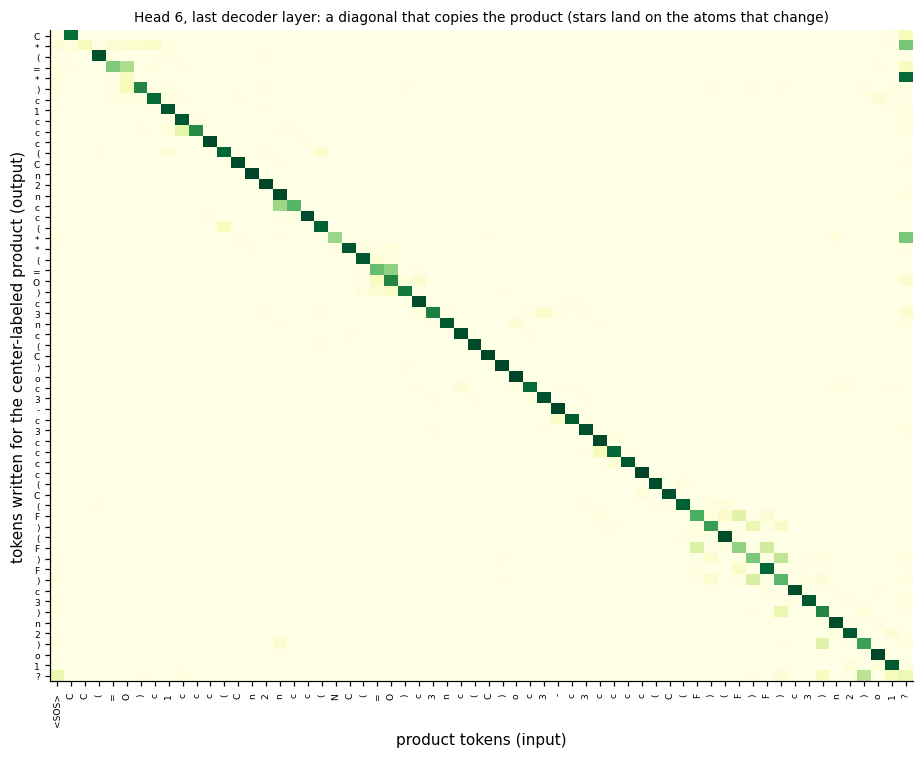

In [ ]:
if CAPSULE:
    prod, otoks, att, ptoks, sep = first; sel = slice(sep + 1, None)                                              # output positions of the center-labeled product
    A6 = att[6][sep:, :len(ptoks)]                                                                               # head 6: rows predict output tokens sep+1 ...
    fig, ax = plt.subplots(figsize=(8.5, 7)); ax.imshow(A6, cmap="YlGn", aspect="auto")
    ax.set_xticks(range(len(ptoks))); ax.set_xticklabels(ptoks, rotation=90, fontsize=6); ax.set_yticks(range(A6.shape[0])); ax.set_yticklabels((otoks[sep + 1:] + ['?'])[:A6.shape[0]], fontsize=6)
    ax.set_xlabel("product tokens (input)"); ax.set_ylabel("tokens written for the center-labeled product (output)"); ax.set_title("Head 6, last decoder layer: a diagonal that copies the product (stars land on the atoms that change)", fontsize=9)
    plt.tight_layout(); plt.show()

## 6. From strings to reactions: the post-processing funnel, and what the Top-$K$ numbers can bear
The model's beam is a list of strings. The authors' code then: (1) **applies** each template to the product with RDKit (`RunReactants`); (2) keeps those that apply (**valid**); (3) removes duplicates; (4) wraps templates with several product-side fragments as **intramolecular**; (5) keeps only the matches whose matched atoms equal the **starred atoms** of the center-labeled product (the **site check**, "working templates"); (6) collapses to **unique sets of canonical reactant SMILES**, in the order of the beam score. The Top-$K$ accuracy is the share of test reactions whose recorded reactant set appears among the first $K$ unique sets. The numbers below are the ones the authors' notebooks saved (RDKit is needed to recompute them; Part II does it).

In [ ]:
funnel = pd.DataFrame([("A (one product, beam 10)", 10, 10, 10, 10, 9, "-", "-"), ("A (test reaction 1, beam 50)", 50, 49, 80, 85, 45, 350, 209),
                       ("B (one product, beam 10)", 10, 10, 10, 10, 9, "-", "-"), ("B (test reaction 1, beam 50)", 50, 98, 98, 98, 47, 98, "-"),
                       ("C (3 x 10 samples x beam 5)", 150, 50, 45, 33, 30, "-", "-"), ("C (test reaction 1: 150 samples x beam 10)", 1500, 866, 1199, 482, 166, 5056, 1464)],
                      columns=["run (saved outputs)", "strings from the beam", "valid", "unique templates incl. intramolecular variants", "working (site check passed)", "unique reactant sets", "reactant sets WITHOUT the site check", "of which unique"])
print(funnel.to_string(index=False))
print("\nthe site check matters: for test reaction 1, Model A's 80 templates would give 350 reactant sets (209 unique) if applied at every matching site; only 85 template applications (45 unique sets) respect the labeled sites;")
print("Model C's 1,199 templates would give 5,056 reactant sets (1,464 unique) without the check, 166 unique with it.   (valid / unique counts are as the authors' printouts define them; they are not all comparable columns)")

                       run (saved outputs)  strings from the beam  valid  unique templates incl. intramolecular variants  working (site check passed)  unique reactant sets reactant sets WITHOUT the site check of which unique
                  A (one product, beam 10)                     10     10                                              10                           10                     9                                    -               -
              A (test reaction 1, beam 50)                     50     49                                              80                           85                    45                                  350             209
                  B (one product, beam 10)                     10     10                                              10                           10                     9                                    -               -
              B (test reaction 1, beam 50)                     50     98                            

In [ ]:
def wilson(k, n, z=1.96):
    p = k / n; den = 1 + z * z / n; c = (p + z * z / (2 * n)) / den; h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den; return c - h, c + h
topk = {"A": [20, 50, 60, 70, 70, 80], "B": [40, 70, 90, 90, 90, 90], "C": [10, 30, 30, 40, 60, 60]}; ks = ["Top-1", "Top-3", "Top-5", "Top-10", "Top-20", "Top-50"]
rows = []
for m, v in topk.items():
    for k, pct in zip(ks, v):
        lo, hi = wilson(round(pct / 10), 10); rows.append((f"Model {m}", k, f"{pct:.0f} %", f"{100 * lo:.0f} to {100 * hi:.0f} %"))
print("the tutorials' saved Top-K results are for the FIRST TEN test molecules:")
print(pd.DataFrame(rows[:6], columns=["", "K", "result on 10 molecules", "95 % interval"]).to_string(index=False))
print("\nModel A's 20 % at Top-1 is 2 of 10, compatible with anything from 6 % to 51 %. These ten-molecule demonstrations show the code works; the accuracy of the models is in the paper's Figure 3 (a figure, not text):")
print("the paper's text says that on the cleaned test set Model B reaches about 80 % Top-10 and, for reactions with at most two reaction centers, 90 %; Model B is GIVEN the true reaction centers, Models A and C are not.")
assert wilson(2, 10)[0] < 0.06 and wilson(2, 10)[1] > 0.5

the tutorials' saved Top-K results are for the FIRST TEN test molecules:
             K result on 10 molecules 95 % interval
Model A  Top-1                   20 %     6 to 51 %
Model A  Top-3                   50 %    24 to 76 %
Model A  Top-5                   60 %    31 to 83 %
Model A Top-10                   70 %    40 to 89 %
Model A Top-20                   70 %    40 to 89 %
Model A Top-50                   80 %    49 to 94 %

Model A's 20 % at Top-1 is 2 of 10, compatible with anything from 6 % to 51 %. These ten-molecule demonstrations show the code works; the accuracy of the models is in the paper's Figure 3 (a figure, not text):
the paper's text says that on the cleaned test set Model B reaches about 80 % Top-10 and, for reactions with at most two reaction centers, 90 %; Model B is GIVEN the true reaction centers, Models A and C are not.


## 7. The data, and the "cleaned" test set
*(Needs the code folder.)* The training data are USPTO-FULL reactions (atom-mapped, Tetko et al. split). The authors found that many test reactions contain **spectators** (solvents, bases, salts, catalysts that the mapping treated as reactants), which no template can sensibly predict; their **cleaned** test set removes every reaction whose recorded reactants include one of the **50 most frequent spectators**.

In [ ]:
import lzma
DS, SPEC = (CAPSULE / "data_AT/dataset") if CAPSULE else None, (CAPSULE / "data_AT/data_pickles/sorted_reagents_spectators.pickle") if CAPSULE else None
files = {k: DS / f"uspto_{k}T.csv.xz" for k in ("train", "val", "test")} if DS else {}
if files and all(f.exists() for f in files.values()):
    n_rows = {k: sum(1 for _ in lzma.open(f, "rt")) - 1 for k, f in files.items()}
    tot = sum(n_rows.values()); print({k: f"{v:,} ({100 * v / tot:.1f} %)" for k, v in n_rows.items()}, "| total", f"{tot:,}")
    sample = pd.read_csv(files["test"], nrows=2); print("columns:", list(sample.columns), "| 'input' is the atom-mapped PRODUCT, 'target' the atom-mapped reactants")
    assert n_rows == {"train": 768_808, "val": 96_092, "test": 96_027}
    print(f"the paper: the cleaned test set is 90.7 % of the original set, i.e. about {0.907 * n_rows['test']:,.0f} of the {n_rows['test']:,} test rows (the authors' own loop drops one unextractable test reaction)")
else:
    print("the USPTO data files are not in this copy of the code folder; skipping the row counts. The paper's numbers: 768,808 / 96,092 / 96,027 reactions.")
if SPEC is not None and SPEC.exists():
    # the spectator table is a numpy array pickle: allow exactly numpy's three array-rebuilding names, nothing else
    data = SPEC.read_bytes(); print("names the spectator pickle imports:", pickle_globals(data))
    _core = getattr(np, "_core", None) or np.core
    class _ArrayOnly(pickle.Unpickler):
        OK = {("numpy.core.multiarray", "_reconstruct"): _core.multiarray._reconstruct, ("numpy._core.multiarray", "_reconstruct"): _core.multiarray._reconstruct, ("numpy", "ndarray"): np.ndarray, ("numpy", "dtype"): np.dtype}
        def find_class(self, m, n):
            if (m, n) in self.OK: return self.OK[(m, n)]
            raise pickle.UnpicklingError(f"refused {m}.{n}")
    spec = _ArrayOnly(io.BytesIO(data)).load(); freq = spec[:, 1].astype(int)
    print(f"\n{len(spec):,} distinct spectator strings, {freq.sum():,} occurrences; the 50 most frequent make up {100 * freq[:50].sum() / freq.sum():.1f} % of them")
    print(pd.DataFrame({"spectator": spec[:12, 0], "occurrences": [f"{f:,}" for f in freq[:12]]}).to_string(index=False))
    assert spec[0, 0] == "O"
else:
    print("the spectator table (sorted_reagents_spectators.pickle, 101 MB) is not in this copy of the code folder; skipping. The paper's numbers: 33,624 distinct strings, the top 50 = 80.6 % of 4,980,159 occurrences.")

{'train': '768,808 (80.0 %)', 'val': '96,092 (10.0 %)', 'test': '96,027 (10.0 %)'} | total 960,927
columns: ['input', 'target'] | 'input' is the atom-mapped PRODUCT, 'target' the atom-mapped reactants
the paper: the cleaned test set is 90.7 % of the original set, i.e. about 87,096 of the 96,027 test rows (the authors' own loop drops one unextractable test reaction)
names the spectator pickle imports: ['ndarray.dtype', 'numpy.core.multiarray._reconstruct', 'numpy.ndarray']

33,624 distinct spectator strings, 4,980,159 occurrences; the 50 most frequent make up 80.6 % of them
    spectator occurrences
            O     368,030
        [Na+]     367,429
      C1CCOC1     241,617
        ClCCl     230,870
           Cl     224,318
     CN(C)C=O     187,135
         [K+]     171,009
           CO     167,591
        [OH-]     146,908
O=C([O-])[O-]     140,813
    CCOC(C)=O     131,482
          CCO     126,273


## 8. Your turn
**Exercise 1 (templates).** Write the anatomy of `[C:1]=[O:2]>>[CH:1]-[OH:2]` (the template of the alcohol oxidation Model B proposed). How many product atoms does it map?

**Exercise 2 (centers).** For `CC(=O)Nc1ccccc1`, which atom indices carry `*` in the center-labeled product of the amide C-N disconnection? Check with `to_center_labeled`.

**Exercise 3 (decoding).** In Section 3 change `p_end` to 0.5 and to 0.05: how do the best lengths change under the three exponents?

**Exercise 4 (parameters).** If the hidden size were 512 with feed-forward width 1024, how many parameters would the network have (vocabulary 83)?

**Exercise 5 (attention).** Run Section 5 on a product of your own. Does head 6 still copy? What does head 6 attend to at the *template* positions (before the underscore)?

**Exercise 6 (intervals).** What is the 95 % interval for 14 of 100 test molecules? How many molecules would you need to pin Top-1 to $\pm3$ percentage points?

In [ ]:
print("Exercise 1:", template_anatomy("[C:1]=[O:2]>>[CH:1]-[OH:2]"))
smi = "CC(=O)Nc1ccccc1"; print("Exercise 2: atoms", [(i, smi[a:b]) for i, (a, b) in enumerate(smiles_atom_spans(smi))][:6], "| C(=O)-N bond -> centers [1, 3]:", to_center_labeled(smi, [1, 3]))
e, dd = transformer_params(83, 83, d=512, ff=1024); print(f"Exercise 4: {e + dd:,} parameters")
print("Exercise 6: 14/100 ->", tuple(round(100 * x) for x in wilson(14, 100)), "| n for +-3 points at p = 0.3:", math.ceil(1.96 ** 2 * 0.3 * 0.7 / 0.03 ** 2))

Exercise 1: {'product_side': '[C:1]=[O:2]', 'reactant_side': '[CH:1]-[OH:2]', 'mapped_atoms': 2, 'unmapped_new_atoms': 0, 'reactant_fragments': 1, 'product_fragments': 1, 'intramolecular': False}
Exercise 2: atoms [(0, 'C'), (1, 'C'), (2, 'O'), (3, 'N'), (4, 'c'), (5, 'c')] | C(=O)-N bond -> centers [1, 3]: C*(=O)*c1ccccc1
Exercise 4: 32,008,787 parameters
Exercise 6: 14/100 -> (9, 22) | n for +-3 points at p = 0.3: 897


## 9. Self-check

In [ ]:
assert sum(transformer_params(83, 83)) == 8_140_115 and sum(transformer_params(82, 82)) == 8_139_346
assert template_anatomy("[C:2]#[CH:1]>>Br-[C:1](-Br)=[CH:2]")["mapped_atoms"] == 2 and template_anatomy(examples["amide from a ketal, an amine and an acid"])["intramolecular"]
assert to_center_labeled("C#CC1(C)CCCCC1=O", [0, 1]) == "*#*C1(C)CCCCC1=O" and len(tokenize("*#*C1(C)CCCCC1=O")) == 18
assert abs(np.mean([len(allseq[i]) for i in np.argsort(-raw)[:5]]) - 1.0) < 1.01 and funnel.shape == (6, 8)
if CAPSULE:
    assert clp_gen == saved and top_tmpl == "[CH:1]>>C-[Si](-C)(-C)-[C:1]" and share[6] > 0.9
    print("All checks passed, including the real-checkpoint checks.")
else:
    print("All checks passed (the real-checkpoint checks were skipped: no code folder).")

All checks passed, including the real-checkpoint checks.


# Part II. Run the authors' code and draw the reactions

> **Read this first.** Part I never applied a template to a molecule. Part II uses the authors' own code from the folder `single_step_retro-main` (`model_library`, `helper.py`), which needs **PyTorch** and **RDKit**: it applies the generated templates to the product with `RunReactants`, applies the site check, collapses duplicates and draws the reactions. Use **Google Colab** (PyTorch is installed there; the cell below installs RDKit) or any Python 3.9+ environment, and run the cells **one by one**. It follows the authors' own tutorial notebook and cross-checks it against the NumPy path of Part I when both are available.
>
> You need the code folder: put `single_step_retro-main` (or its zip) next to the notebook, into `/content`, or into My Drive: the finder in the first code cell locates it (or set `CAPSULE_DIR`). The code is under the MIT license (Copyright 2024 Yu Shee); this notebook contains none of its code.
>
> **If the folder is not available in your Colab session, Part II does not run: the first cell then says what is missing, and you can run your own prompt at https://models.batistalab.com/ instead.**

In [ ]:
!pip install -q rdkit

In [ ]:
import subprocess, importlib, importlib.util
MODELS_SITE = "https://models.batistalab.com/"
def models_site_notice(reason):
    print("\nPart II cannot run here: " + reason + ".")
    print("To run your own prompt (your own product molecule) without installing anything, use the group's web service:")
    print("    " + MODELS_SITE)
if CAPSULE is None:                                       # not found by the first cell: try again (a zip next to the notebook is unzipped)
    zips = [z for d in (Path("."), Path("/content")) for z in sorted(d.glob("single_step_retro*.zip"))]
    if zips: subprocess.run(["unzip", "-q", "-o", str(zips[0])], check=True)
    CAPSULE = find_capsule()
have = lambda rel: CAPSULE is not None and (CAPSULE / rel).exists()
def find_model_file(pattern):
    """The model checkpoint inside the code folder: single_step_retro-main/model_checkpoints/<pattern>."""
    return next(iter(sorted((CAPSULE / "model_checkpoints").glob(pattern))), None) if CAPSULE else None
MODEL_A_CKPT = find_model_file("ModelA*.cpth")
needed = {"the folder single_step_retro-main": CAPSULE is not None,
          "the Model A checkpoint (model_checkpoints/ModelA*.cpth)": MODEL_A_CKPT is not None,
          "the authors' code (helper.py, model_library/modelA)": have("helper.py") and have("model_library/modelA/ModelClass.py"),
          "the dictionary (data_AT/data_pickles/ModelA_dictionary.pickle)": have("data_AT/data_pickles/ModelA_dictionary.pickle"),
          "PyTorch": importlib.util.find_spec("torch") is not None, "RDKit": importlib.util.find_spec("rdkit") is not None}
print("code folder:", CAPSULE)
for mod in ("torch", "rdkit"):
    try: m_ = importlib.import_module(mod); print(f"{mod:6s} {getattr(m_, '__version__', 'installed')}")
    except Exception as e: print(f"{mod:6s} NOT AVAILABLE ({type(e).__name__})")
for what, ok in needed.items(): print(f"  {'found  ' if ok else 'MISSING'}  {what}")
HAVE_TORCH_RDKIT = all(needed.values())
if HAVE_TORCH_RDKIT: print("Part II can run; the model checkpoint is", MODEL_A_CKPT.name)
else: models_site_notice("missing: " + "; ".join(w for w, ok in needed.items() if not ok))


code folder: /content/drive/MyDrive/Colab Notebooks/ML/temp/Blogs/single_step_retro-main
torch  2.14.1+cpu
rdkit  2026.09.2
  found    the folder single_step_retro-main
  found    the Model A checkpoint (model_checkpoints/ModelA*.cpth)
  found    the authors' code (helper.py, model_library/modelA)
  found    the dictionary (data_AT/data_pickles/ModelA_dictionary.pickle)
  found    PyTorch
  found    RDKit
Part II can run; the model checkpoint is ModelA_AT_DATA_256DIM_0Radius_6Layer_Seq2Seq_112_Batch_5e5_LR_810EP_MASK_ATOM.cpth


In [ ]:
# load the authors' modules and build Model A exactly as in their tutorial (their code expects to run from the code folder)
if HAVE_TORCH_RDKIT:
    import torch
    from rdkit import Chem, RDLogger
    RDLogger.DisableLog("rdApp.*")
    os.chdir(CAPSULE); sys.path.insert(0, str(CAPSULE))
    from helper import draw_reverse_template, draw_reaction
    from data_AT.data_helper import Tokenizer
    from model_library.modelA.ModelClass import Encoder, Decoder, Conditioner, Seq2Seq
    from model_library.modelA.GenerationFunctions import Conditioned_Batch_Beam_Search, process_beam_results_list

    with open("data_AT/data_pickles/ModelA_dictionary.pickle", "rb") as fh: smiledict, invdict = pickle.load(fh)      # a plain dictionary pickle (we checked in Part I that it imports nothing)
    product_length, HID, device = 310, 256, torch.device("cuda" if torch.cuda.is_available() else "cpu")
    cond_enc = Encoder(len(smiledict) + 1, HID, 6, HID // 32, 2 * HID, 0.1, max_length=product_length)
    conditioner = Conditioner(cond_enc, seq_len=10)
    dec = Decoder(len(invdict), HID, 6, HID // 32, 2 * HID, 0.1, max_length=350)
    modelA = Seq2Seq(dec, conditioner, len(smiledict), len(smiledict), bottle_len=10)
    print("parameters:", f"{sum(p.numel() for p in modelA.parameters() if p.requires_grad):,}", "(the authors print 8,140,115)")
    ckpt_path = str(MODEL_A_CKPT)
    checkpoint = torch.load(ckpt_path, map_location=device)          # NOTE: torch.load unpickles; we inspected this file in Part I (only tensor-storage names)
    print(modelA.load_state_dict(checkpoint["model_state_dict"])); modelA.to(device).eval();
else:
    print("Part II is skipped: see the message above. To run your own prompt without the code folder, use https://models.batistalab.com/")

parameters: 8,140,115 (the authors print 8,140,115)
<All keys matched successfully>


In [ ]:
# generate with the authors' beam search and post-process with their functions (RDKit applies the templates)
if HAVE_TORCH_RDKIT:
    tokenizer = Tokenizer("character_consider_atoms")
    TARGET = "C#CC1(C)CCCCC1=O"                                                         # change here; the paper's key intermediate has this shape
    target = Chem.MolToSmiles(Chem.MolFromSmiles(TARGET), isomericSmiles=True, canonical=True)
    ids = [smiledict[t] for t in tokenizer.tokenize(target, product=True)]; ids += [len(smiledict)] * (product_length - len(ids))
    x = torch.LongTensor(ids).view(-1, product_length).to(device)
    t0 = time.time()
    with torch.no_grad():
        beam = Conditioned_Batch_Beam_Search(x, None, modelA, device, smiledict, invdict, max_len=349, beam_size=10)
    print(f"beam search: {time.time() - t0:.0f} s on {device}")
    beam_list = np.array(beam).reshape((-1, 2)).tolist()
    sorted_check, working_templates, unique_reactant_sets, idx = process_beam_results_list(beam_list, target, Keep_Chirality=True)
    print(f"\n{len(unique_reactant_sets)} unique reactant sets")

100%|██████████| 347/347 [06:02<00:00,  1.05s/it]

beam search: 363 s on cpu
Beam Results Length: 10
Valid Templates: 10
Unique Templates: 10
Total UV Templates: 10
# of Intra Templates: 7
# of Non-Intra Templates: 3
Working Template Count: 10
# of Unique Reactant Sets: 9

9 unique reactant sets


CC1(C#C[Si](C)(C)C)CCCCC1=O>>C#CC1(C)CCCCC1=O
CI.C#CC1CCCCC1=O>>C#CC1(C)CCCCC1=O
CC1(C=O)CCCCC1=O.O=C([O-])[O-]>>C#CC1(C)CCCCC1=O
C#CC1(C)CCCCC1O>>C#CC1(C)CCCCC1=O


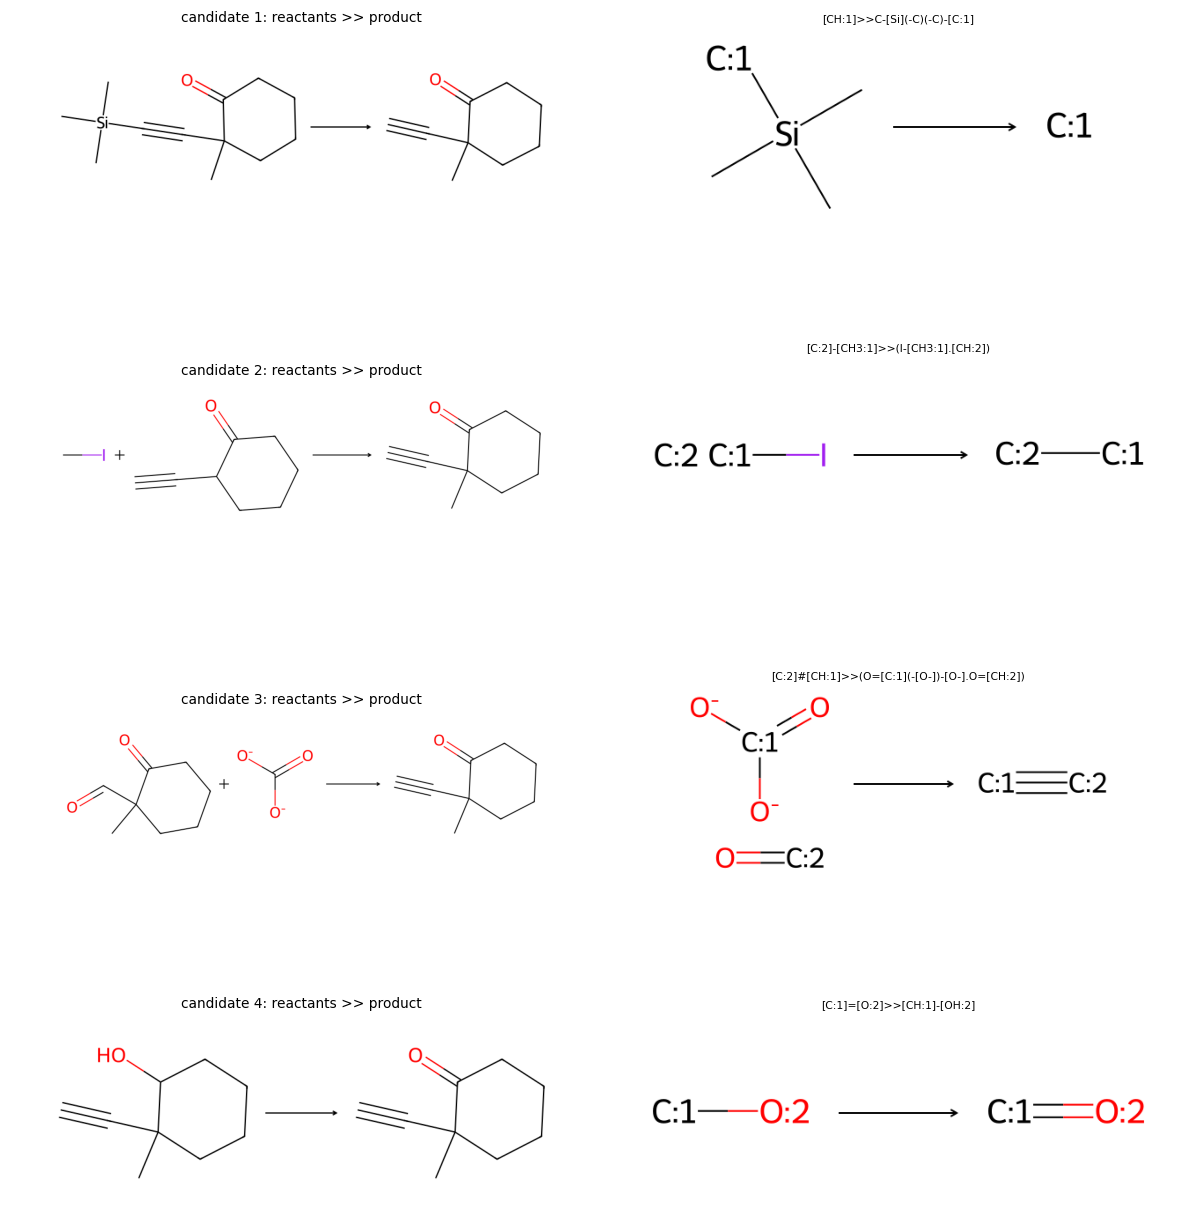

In [ ]:
# draw the top reactions and their templates with the authors' drawing functions
if HAVE_TORCH_RDKIT and unique_reactant_sets:
    product_mol = Chem.MolFromSmiles(target); n_show = min(4, len(unique_reactant_sets))
    fig, axes = plt.subplots(n_show, 2, figsize=(11, 3.2 * n_show), squeeze=False)
    for i in range(n_show):
        img = draw_reaction([Chem.MolFromSmiles(r) for r in unique_reactant_sets[i]], product_mol, 300)                 # prints the reaction SMILES
        tmpl = working_templates[idx[i]]; timg = draw_reverse_template(tmpl, 220)
        axes[i, 0].imshow(img); axes[i, 0].set_title(f"candidate {i + 1}: reactants >> product", fontsize=9); axes[i, 1].imshow(timg); axes[i, 1].set_title(tmpl, fontsize=7)
        axes[i, 0].axis("off"); axes[i, 1].axis("off")
    plt.tight_layout(); plt.show()

In [ ]:
# cross-check: do the authors' PyTorch model and our NumPy re-implementation write the same top template?
if HAVE_TORCH_RDKIT and CAPSULE is not None:
    sdA_np = load_checkpoint_numpy(Path(ckpt_path))["model_state_dict"]; npA = TemplateTransformerNP(sdA_np)
    res_np = sorted(beam_search(npA, smiledict, invdict, tokenize(target), beam_size=10), key=lambda r: -r[1])
    res_torch = sorted([(b[0], float(b[1])) for b in beam_list], key=lambda r: -r[1])
    print("PyTorch top-3:", [r[0].split("_")[0] for r in res_torch[:3]]); print("NumPy   top-3:", [r[0].split("_")[0] for r in res_np[:3]])
    print("same top template:", res_torch[0][0].split("_")[0] == res_np[0][0].split("_")[0], "| same set of 10 strings:", {r[0] for r in res_torch} == {r[0] for r in res_np})

PyTorch top-3: ['[CH:1]>>C-[Si](-C)(-C)-[C:1]', '[C:2]-[CH3:1]>>I-[CH3:1].[CH:2]', '[C:2]#[CH:1]>>O=[C:1](-[O-])-[O-].O=[CH:2]']
NumPy   top-3: ['[CH:1]>>C-[Si](-C)(-C)-[C:1]', '[C:2]-[CH3:1]>>I-[CH3:1].[CH:2]', '[C:2]#[CH:1]>>O=[C:1](-[O-])-[O-].O=[CH:2]']
same top template: True | same set of 10 strings: True


### What to look for
* **Site check.** Compare the number of unique reactant sets with and without the check (the authors' `check_found_or_not` prints both for a test reaction): the center-labeled product is what keeps the candidate list short.
* **Chemical sense.** Model A mixes protections, functional-group interconversions and real disconnections; the template tells you which atoms are involved, so a chemist can judge each proposal.
* **Failures.** Templates that match nowhere are dropped (valid < beam size); templates with several product-side fragments are treated as intramolecular.
* **If PyTorch or RDKit versions clash:** the authors' README pins Python 3.9, PyTorch 1.13.1 and RDKit 2022.9.5; newer versions are said to work.